# 04 · Error analysis

Where does each model win or fail, and why? Uses out-of-sample predictions only:
- **CV**: out-of-fold predictions on 53 trips (`experiments/phase3_oof.parquet`), the larger sample, used as the main lens;
- **test**: the 13 held-out trips (`experiments/phase3_test_predictions.parquet`), as a check.

Conditions describe the **5 km stretch being predicted** (`src.data.targets.horizon_conditions`). They use future data, so
they are for analysis only, never model inputs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data.load import SAMPLE_PERIOD_S
from src.data.targets import build_anchors, horizon_conditions
from src.features.build import tabular_features

EXP = ROOT / "experiments"
FIG_DIR = ROOT / "figures" / "error_analysis"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "text.color": "#0b0b0b", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})
M = ["baseline_global_avg", "ridge", "lgbm", "gru"]
LABEL = {"baseline_global_avg": "baseline: global avg", "ridge": "Ridge", "lgbm": "LightGBM", "gru": "GRU"}
COLOR = {"baseline_global_avg": "#898781", "ridge": "#2a78d6", "lgbm": "#1baf7a", "gru": "#eb6834"}

clean = pd.read_parquet(ROOT / "data" / "processed" / "trips_clean.parquet")
anchors = build_anchors(clean)
info = pd.concat([anchors[["trip_id", "row"]], horizon_conditions(clean, anchors),
                  tabular_features(clean, anchors)[["speed_mean_1km", "ambient_temp_c"]]], axis=1)

def with_conditions(df: pd.DataFrame) -> pd.DataFrame:
    """Attach future-stretch conditions and condition bins to a prediction table."""
    df = df.merge(info, on=["trip_id", "row"])
    return df.assign(
        temperature=pd.cut(df.ambient_temp_c, [-10, 5, 15, 40], labels=["cold <5 °C", "mild 5–15", "warm >15"]),
        road=pd.cut(df.future_speed_kmh, [0, 50, 80, 200], labels=["city <50 km/h", "mixed 50–80", "highway >80"]),
        terrain=pd.cut(df.future_abs_grade_pct, [-1, 0.5, 1.0, 100], labels=["flat <0.5 %", "rolling 0.5–1", "hilly >1 %"]),
        trip_phase=pd.cut(df.km_in_segment, [0, 5, 15, 100], labels=["early 1–5 km", "mid 5–15", "late 15+"]),
    )

oof = with_conditions(pd.read_parquet(EXP / "phase3_oof.parquet"))
test = with_conditions(pd.read_parquet(EXP / "phase3_test_predictions.parquet"))
print(f"CV: {len(oof):,} anchors / {oof.trip_id.nunique()} trips;  test: {len(test):,} anchors / {test.trip_id.nunique()} trips")

CV: 7,546 anchors / 53 trips;  test: 1,738 anchors / 13 trips


## 1. Error by condition

Rate MAE (%SoC/km) per condition. `trips` = how many trips contribute; cells with few trips are anecdotes, not evidence.

In [2]:
CONDS = ["temperature", "road", "terrain", "trip_phase"]

def by_condition(df: pd.DataFrame, cond: str) -> pd.DataFrame:
    """MAE per model within each level of `cond`, with anchor and trip counts."""
    g = df.groupby(cond, observed=True)
    out = pd.DataFrame({"anchors": g.size(), "trips": g.trip_id.nunique()})
    for m in M:
        out[LABEL[m]] = g.apply(lambda s: (s[f"pred_{m}"] - s.rate_next).abs().mean(), include_groups=False)
    return out

for name, df in [("CV", oof), ("test", test)]:
    print(f"==== {name} ====")
    for c in CONDS:
        display(by_condition(df, c).round(3))

==== CV ====


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
temperature,,,,,,
cold <5 °C,2057,18,0.208,0.164,0.169,0.169
mild 5–15,2254,19,0.127,0.130,0.135,0.142
warm >15,3235,25,0.205,0.130,0.123,0.128


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
road,,,,,,
city <50 km/h,2218,45,0.183,0.129,0.127,0.124
mixed 50–80,2695,47,0.185,0.140,0.145,0.153
highway >80,2633,32,0.180,0.146,0.145,0.149


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
terrain,,,,,,
flat <0.5 %,6344,53,0.170,0.128,0.129,0.134
rolling 0.5–1,761,19,0.209,0.152,0.146,0.145
hilly >1 %,441,5,0.316,0.280,0.277,0.269


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
trip_phase,,,,,,
early 1–5 km,2066,53,0.178,0.133,0.136,0.140
mid 5–15,3417,51,0.182,0.129,0.125,0.131
late 15+,2063,12,0.188,0.161,0.166,0.168


==== test ====


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
temperature,,,,,,
cold <5 °C,767,7,0.173,0.160,0.201,0.210
mild 5–15,518,6,0.210,0.186,0.195,0.196
warm >15,453,4,0.226,0.252,0.242,0.237


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
road,,,,,,
city <50 km/h,321,10,0.095,0.166,0.214,0.292
mixed 50–80,404,12,0.206,0.167,0.184,0.194
highway >80,1013,8,0.227,0.210,0.219,0.195


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
terrain,,,,,,
flat <0.5 %,1444,13,0.176,0.171,0.193,0.192
rolling 0.5–1,294,4,0.303,0.296,0.291,0.315


,anchors,trips,baseline: global avg,Ridge,LightGBM,GRU
trip_phase,,,,,,
early 1–5 km,498,13,0.207,0.190,0.204,0.192
mid 5–15,725,11,0.188,0.167,0.194,0.202
late 15+,515,2,0.202,0.229,0.238,0.248


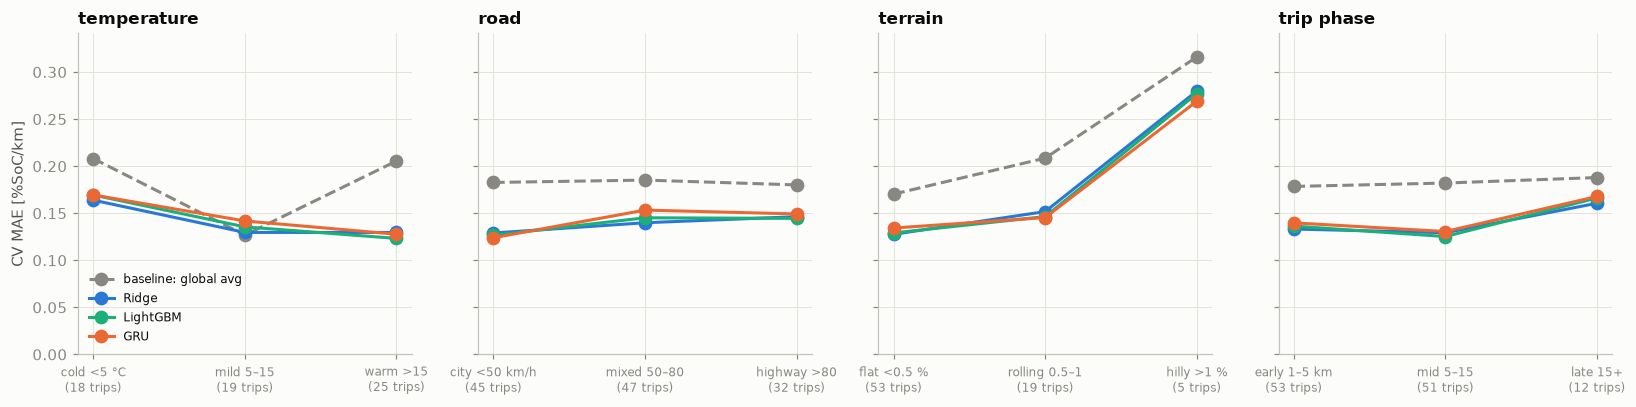

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
ymax = max(by_condition(oof, c)[[LABEL[m] for m in M]].to_numpy().max() for c in CONDS) * 1.08
for ax, c in zip(axes, CONDS):
    t = by_condition(oof, c)
    x = np.arange(len(t))
    for m in M:
        ax.plot(x, t[LABEL[m]], marker="o", ms=8, color=COLOR[m], label=LABEL[m],
                ls="--" if m.startswith("baseline") else "-")
    ax.set_xticks(x); ax.set_xticklabels([f"{i}\n({n} trips)" for i, n in zip(t.index, t.trips)], fontsize=8)
    ax.set_title(c.replace("_", " ")); ax.set_ylim(0, ymax)
axes[0].set_ylabel("CV MAE [%SoC/km]"); axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIG_DIR / "error_by_condition_cv.png", bbox_inches="tight"); plt.show()

## 2. Trip level vs. within the trip

Split the target into the **trip's average rate** (what kind of trip is this?) and the **deviation from it** (what is
the road doing next?). How much of each does a model capture?
- *trip-level R²*: trip-mean prediction vs trip-mean actual (1 = perfect, 0 = no better than one constant).
- *within-trip corr*: correlation of the prediction's deviation from its trip mean with the actual deviation.

In [4]:
def level_vs_within(df: pd.DataFrame) -> pd.DataFrame:
    """Share of variance within trips, and how well each model tracks trip level vs within-trip swings."""
    trip_mean = df.groupby("trip_id").rate_next.transform("mean")
    dev = df.rate_next - trip_mean
    rows = {}
    for m in M:
        p = df[f"pred_{m}"]
        g = df.assign(p=p).groupby("trip_id")[["p", "rate_next"]].mean()
        r2 = 1 - ((g.p - g.rate_next) ** 2).sum() / ((g.rate_next - g.rate_next.mean()) ** 2).sum()
        pdev = p - p.groupby(df.trip_id).transform("mean")
        rows[LABEL[m]] = {"trip-level R²": r2,
                          "within-trip corr": np.corrcoef(dev, pdev)[0, 1] if pdev.std() > 0 else np.nan,
                          "within-trip std (pred)": pdev.std()}
    out = pd.DataFrame(rows).T
    out.attrs["within_share"] = dev.var() / df.rate_next.var()
    out.attrs["within_std_actual"] = dev.std()
    return out

for name, df in [("CV", oof), ("test", test)]:
    t = level_vs_within(df)
    print(f"{name}: {t.attrs['within_share']:.0%} of target variance is WITHIN trips; "
          f"actual within-trip std {t.attrs['within_std_actual']:.3f} %SoC/km")
    display(t.round(2))

CV: 44% of target variance is WITHIN trips; actual within-trip std 0.148 %SoC/km


,trip-level R²,within-trip corr,within-trip std (pred)
baseline: global avg,-0.07,NaN,0.00
Ridge,0.61,0.20,0.05
LightGBM,0.60,0.16,0.04
GRU,0.54,0.20,0.08


test: 82% of target variance is WITHIN trips; actual within-trip std 0.206 %SoC/km


,trip-level R²,within-trip corr,within-trip std (pred)
baseline: global avg,-0.38,NaN,0.00
Ridge,0.18,0.22,0.05
LightGBM,0.01,-0.11,0.05
GRU,-0.18,0.04,0.08


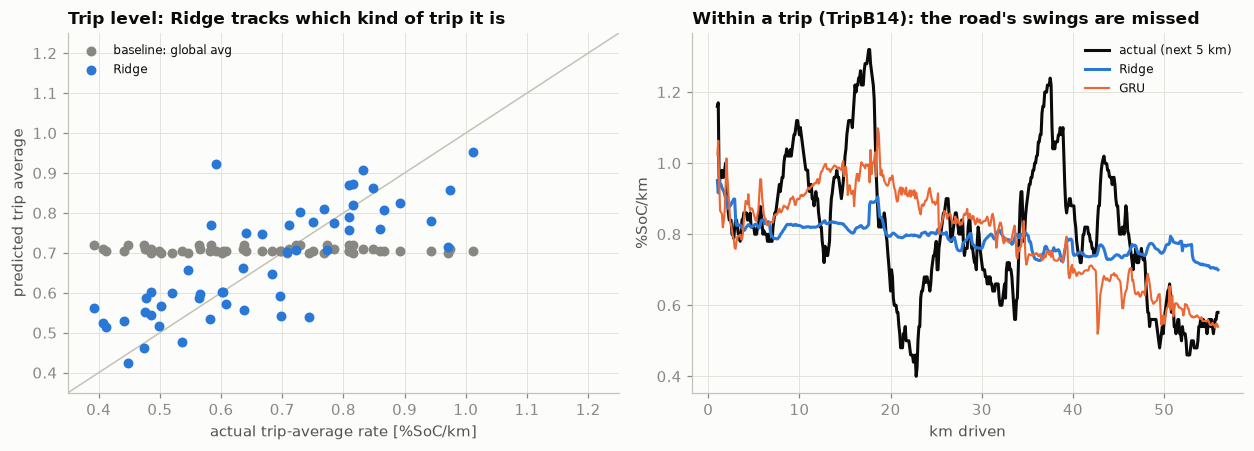

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
g = oof.groupby("trip_id").agg(actual=("rate_next", "mean"), ridge=("pred_ridge", "mean"),
                               base=("pred_baseline_global_avg", "mean"), series=("series", "first"))
lim = [0.35, 1.25]
axes[0].plot(lim, lim, color="#c3c2b7", lw=1)
axes[0].scatter(g.actual, g.base, s=30, color=COLOR["baseline_global_avg"], label="baseline: global avg", zorder=3)
axes[0].scatter(g.actual, g.ridge, s=30, color=COLOR["ridge"], label="Ridge", zorder=3)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("actual trip-average rate [%SoC/km]"); axes[0].set_ylabel("predicted trip average")
axes[0].set_title("Trip level: Ridge tracks which kind of trip it is"); axes[0].legend(fontsize=8)

tid = oof.groupby("trip_id").size().idxmax()
t = oof[oof.trip_id == tid]
axes[1].plot(t.km_in_segment, t.rate_next, color="#0b0b0b", label="actual (next 5 km)")
axes[1].plot(t.km_in_segment, t.pred_ridge, color=COLOR["ridge"], label="Ridge")
axes[1].plot(t.km_in_segment, t.pred_gru, color=COLOR["gru"], lw=1.4, label="GRU")
axes[1].set_xlabel("km driven"); axes[1].set_ylabel("%SoC/km")
axes[1].set_title(f"Within a trip ({tid}): the road's swings are missed"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "level_vs_within.png", bbox_inches="tight"); plt.show()

## 3. What if the model knew the road ahead? (oracle experiment)

From `python -m src.models.run_oracle`: the selected Ridge, re-run in the same CV with the **future** stretch's mean speed
and grade added as features. In a real car these would have to come from navigation. Upper bound only, never deployed.

In [6]:
oracle = pd.read_csv(EXP / "phase4_oracle.csv").set_index("variant")
oracle["MAE change vs deployed"] = oracle.mae_rate / oracle.mae_rate.iloc[0] - 1
oracle[["mae_rate", "rmse_rate", "mae_dte_km", "MAE change vs deployed"]].round(3)

,mae_rate,rmse_rate,mae_dte_km,MAE change vs deployed
variant,,,,
deployed (past only),0.139,0.177,23.606,0.000
+ future speed,0.125,0.161,21.635,-0.102
+ future grade,0.132,0.167,22.143,-0.048
+ future speed & grade,0.119,0.153,20.577,-0.141


## 4. Why trips start expensive in winter (checks the Phase 2 hypothesis)

Heater power and cabin temperature by minutes since the trip (segment) started, winter trips only (heater valid).

,heater_kw,cabin_c,trips
bin,,,
"(0, 2]",4.03,14.42,38
"(2, 5]",2.71,16.16,38
"(5, 10]",1.58,21.49,37
"(10, 15]",1.20,24.28,35
"(15, 20]",1.21,23.92,32
"(20, 30]",1.23,24.08,20
"(30, 60]",1.01,25.41,8


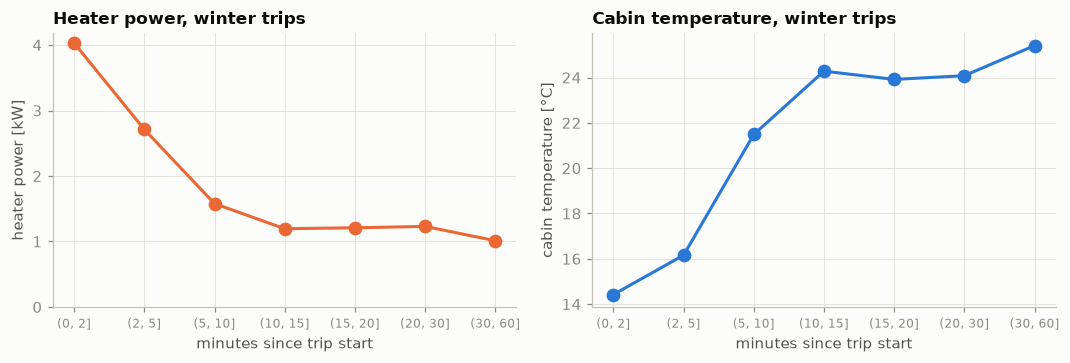

In [7]:
b = clean[(clean.series == "B") & clean.heater_power_kw.notna()].copy()
b["minutes"] = (b.time_s - b.groupby(["trip_id", "segment"]).time_s.transform("first")) / 60
b["bin"] = pd.cut(b.minutes, [0, 2, 5, 10, 15, 20, 30, 60])
warm = b.groupby("bin", observed=True).agg(heater_kw=("heater_power_kw", "mean"), cabin_c=("cabin_temp_c", "mean"),
                                           trips=("trip_id", "nunique"))
display(warm.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(len(warm)); labels = [str(i) for i in warm.index]
axes[0].plot(x, warm.heater_kw, marker="o", ms=8, color="#eb6834"); axes[0].set_ylabel("heater power [kW]")
axes[1].plot(x, warm.cabin_c, marker="o", ms=8, color="#2a78d6"); axes[1].set_ylabel("cabin temperature [°C]")
for ax, title in zip(axes, ["Heater power, winter trips", "Cabin temperature, winter trips"]):
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.set_xlabel("minutes since trip start"); ax.set_title(title)
axes[0].set_ylim(0, None)
fig.tight_layout(); fig.savefig(FIG_DIR / "winter_warmup.png", bbox_inches="tight"); plt.show()